# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import UAVOD10Dataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv 

## Visualize images and objects witn bounding boxes

Total number of patches: 844


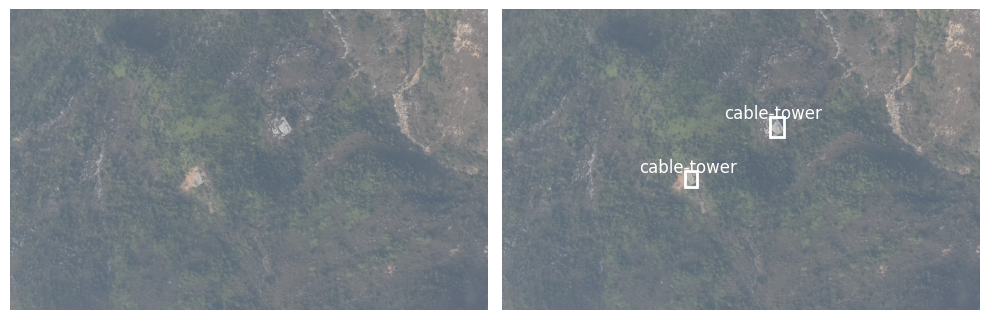

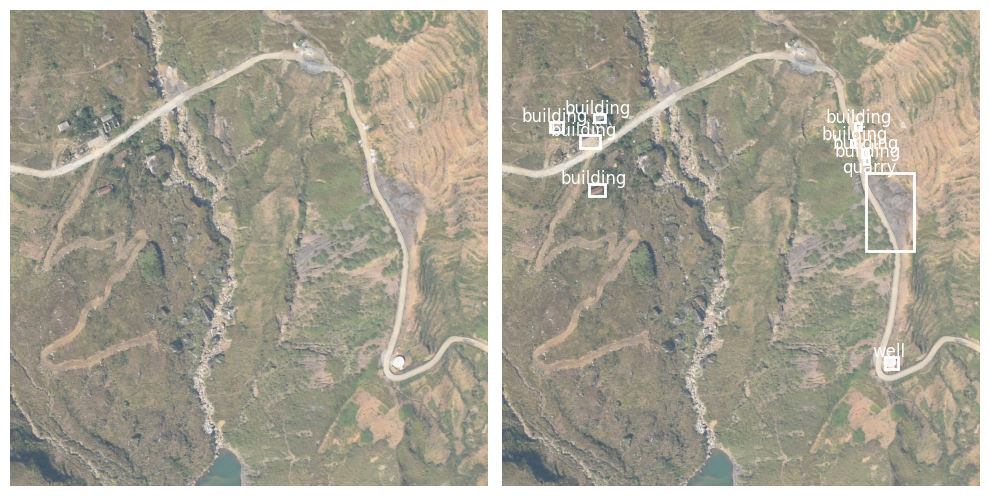

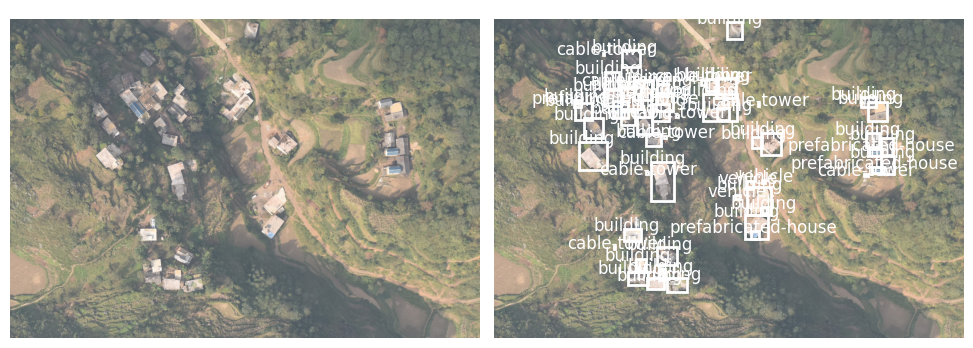

In [6]:
dataset_config = {
    "image_dir": "/home/dragik/data/FAIR_EO/UAVOD10/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/UAVOD10/Annotations/",
}
dataset = UAVOD10Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

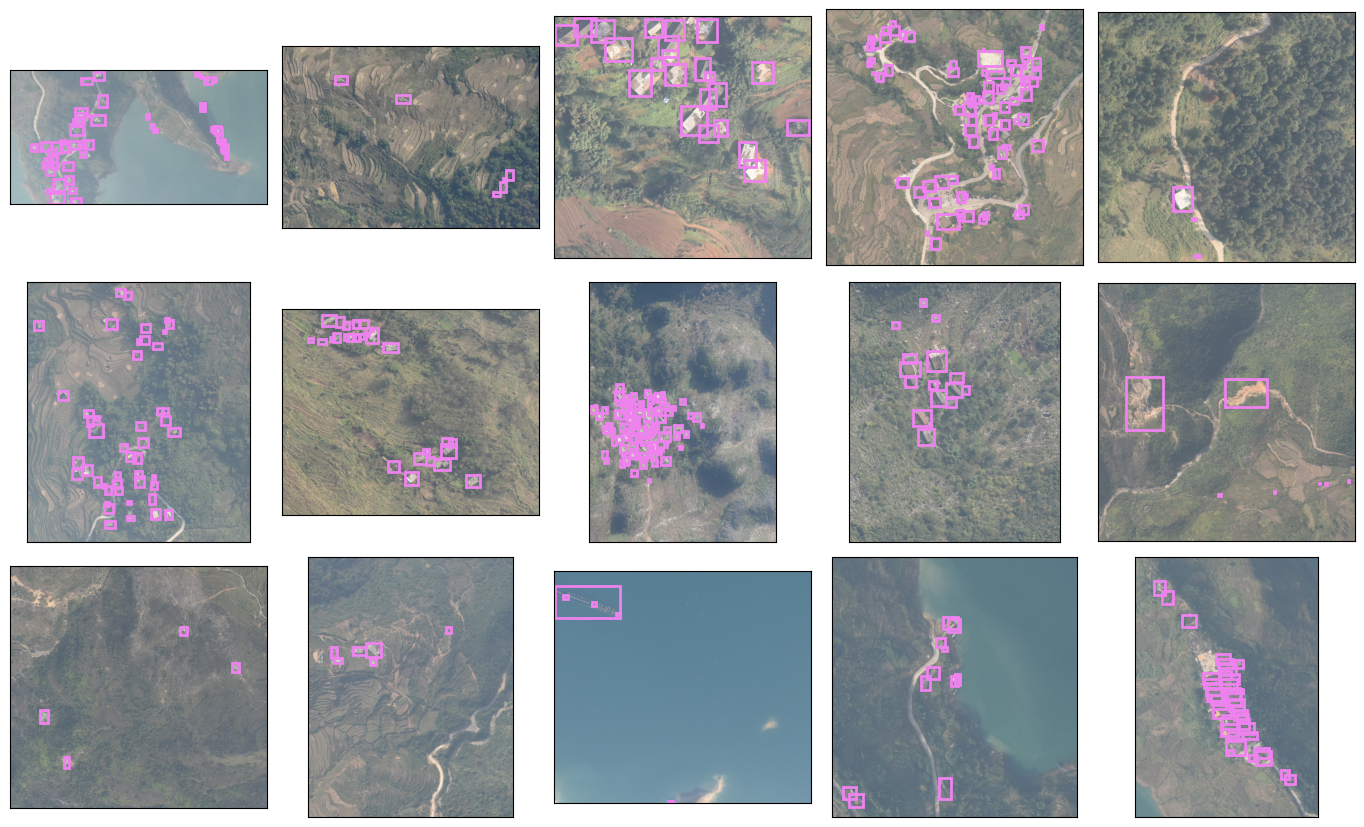

In [7]:
dataset.show_batch(15);

In [8]:
dataset.data_distribution_table()

,Label,Count
0,well,678
1,vehicle,493
2,ship,1027
3,quarry,83
4,prefabricated-house,2059
5,pool,49
6,landslide,40
7,cultivation-mesh-cage,264
8,cable-tower,607
9,building,13034


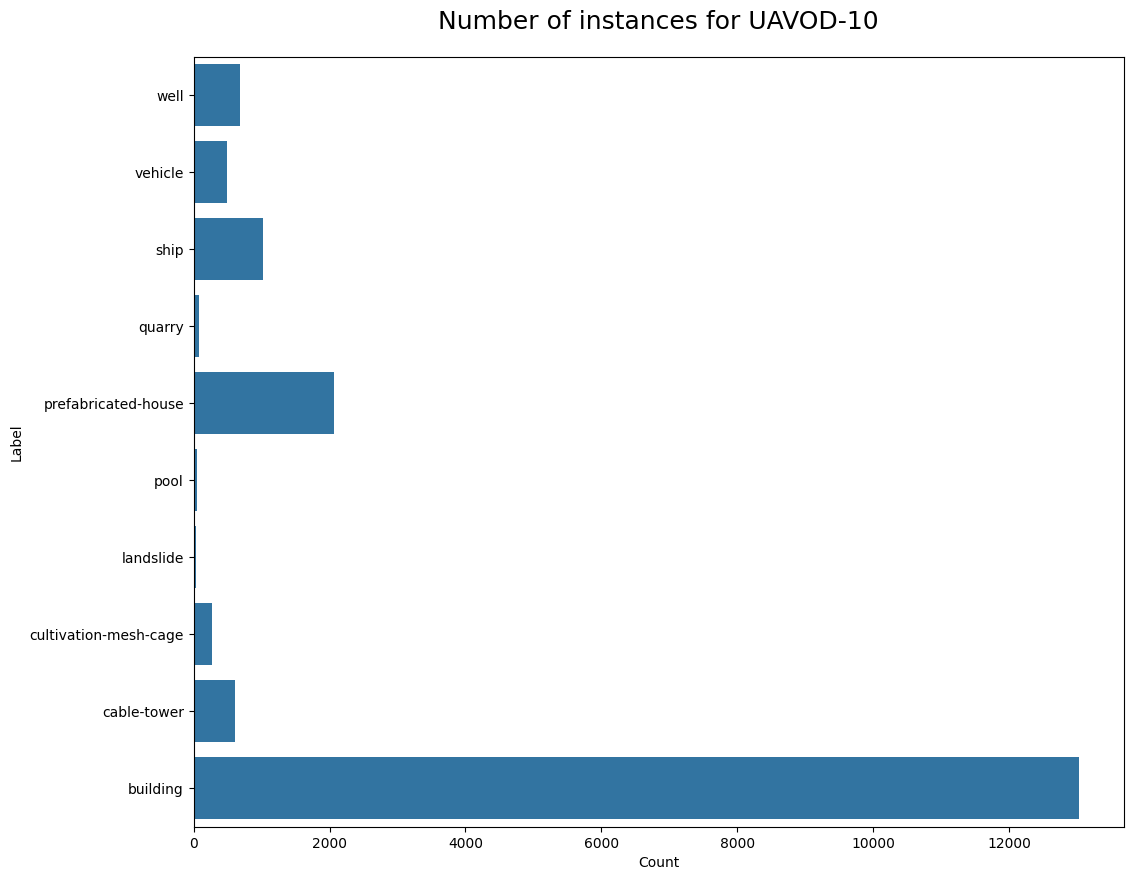

In [10]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "/home/dragik/data/FAIR_EO/UAVOD10/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/UAVOD10/Annotations/",
    "csv_file": "/home/dragik/data/FAIR_EO/UAVOD10/ImageSets/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = UAVOD10Dataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 676


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/UAVOD10/experiments/"
model_config = {
    "num_classes": 11,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 13:36:31,726 INFO Starting training.
training: 100%|██████████| 85/85 [00:29<00:00,  2.92it/s]
2025-05-22 13:37:01,205 INFO epoch: 1, time: 29, loss:  1.18094
testing on train set: 100%|██████████| 85/85 [00:17<00:00,  4.75it/s]
2025-05-22 13:37:35,312 INFO map:0.08937083184719086, map_50:0.1916303038597107, map_75:0.0685497522354126, map_small:0.0783654972910881, map_medium:0.1303049772977829, map_large:0.029688481241464615, mar_1:0.02659694105386734, mar_10:0.09745683521032333, mar_100:0.12487222254276276, mar_small:0.10894989222288132, mar_medium:0.1617296040058136, mar_large:0.03999999910593033, map_per_class:tensor(0.2864), tensor(0.0240), tensor(0.1873), tensor(0.), tensor(0.), tensor(0.3222), tensor(0.), tensor(0.), tensor(0.), tensor(0.0738), mar_100_per_class:tensor(0.3922), tensor(0.0332), tensor(0.2932), tensor(0.), tensor(0.), tensor(0.4137), tensor(0.), tensor(0.), tensor(0.), tensor(0.1164), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), te

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "/home/dragik/data/FAIR_EO/UAVOD10/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/UAVOD10/Annotations/",
    "csv_file": "/home/dragik/data/FAIR_EO/UAVOD10/ImageSets/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = UAVOD10Dataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 84


2025-05-22 13:46:50,532 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar
2025-05-22 13:46:50,934 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 11/11 [00:03<00:00,  3.53it/s]


[{'map': 0.22694934904575348,
  'map_50': 0.4179060459136963,
  'map_75': 0.22634902596473694,
  'map_small': 0.2217966765165329,
  'map_medium': 0.3052145540714264,
  'map_large': 0.20000000298023224,
  'mar_1': 0.09400763362646103,
  'mar_10': 0.2690941095352173,
  'mar_100': 0.29204124212265015,
  'mar_small': 0.29912617802619934,
  'mar_medium': 0.3631161153316498,
  'mar_large': 0.20000000298023224,
  'map_per_class': [tensor(0.3513),
   tensor(0.0908),
   tensor(0.4337),
   tensor(0.),
   tensor(0.5110),
   tensor(0.3682),
   tensor(0.2439),
   tensor(0.1088),
   tensor(0.0125),
   tensor(0.1493)],
  'mar_100_per_class': [tensor(0.4484),
   tensor(0.1000),
   tensor(0.5414),
   tensor(0.),
   tensor(0.5833),
   tensor(0.4356),
   tensor(0.3750),
   tensor(0.1367),
   tensor(0.0222),
   tensor(0.2778)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32),
   t

## Predictions

2025-05-22 13:52:53,331 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar
2025-05-22 13:52:53,682 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar at epoch 11


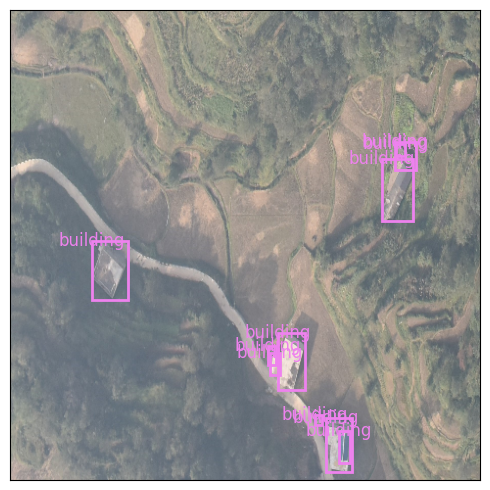

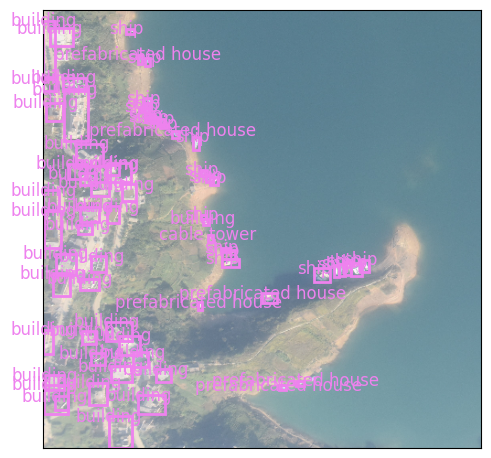

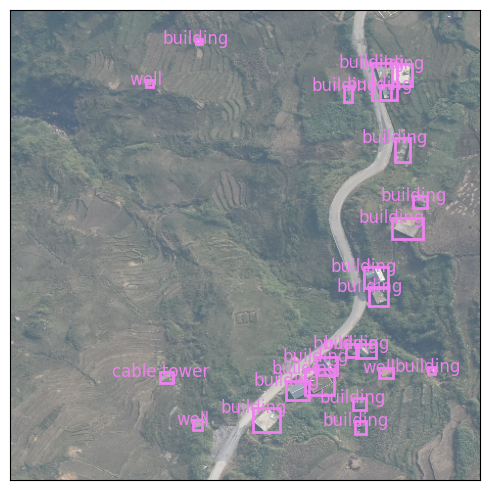

In [11]:
model_config = {
    "num_classes": 11,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/UAVOD10/experiments/checkpoint.pth.tar"
labels = ['no-data','building','cable tower','cultivation mesh cage','landslide','pool','prefabricated house','quarry','ship','vehicle','well']
transform = Resize()
model.load_model(model_path)

csv_file = "/home/dragik/data/FAIR_EO/UAVOD10/ImageSets/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/UAVOD10/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/UAVOD10/' + test_list[5])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/UAVOD10/' + test_list[10])
fig = model.detect_objects(image, labels, transform)